**SAPIANS** · SCC5819 · MÓDULO 00 — A BASE SRAG · BALANCEAMENTO DO XGBOOST

# Balancear melhora qual aspecto do modelo?

Mantemos a amostra de treino e a avaliação temporal do curso. Agora comparamos
as estratégias de balanceamento permitindo ajustar os hiperparâmetros em cada
uma. Este caderno lê a evidência agregada registrada; não treina modelos, não
carrega fichas individuais e não executa uma busca ao ser aberto.

[README do módulo](../README.md) · [protocolo](../COURSE_STUDY.md) ·
[internals](srag_sample_balance_internals.ipynb)

---

**Objetivos.** Separar amostragem de balanceamento; distinguir o controle com
parâmetros originais dos finalistas ajustados; ler log loss, discriminação e
calibração na distribuição real; reconhecer o limite exploratório do teste.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import os
import pathlib
import sys
import tempfile

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd

RANDOM_STATE = 42
REPO = pathlib.Path(os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())).resolve()
while REPO != REPO.parent and not (REPO / "tools/sapians.py").exists():
    REPO = REPO.parent
if not (REPO / "tools/sapians.py").exists():
    raise RuntimeError("Abra este caderno em um checkout do repositório.")
RECORD = pathlib.Path(os.environ.get(
    "SAPIANS_SAMPLE_BALANCE_RECORD",
    REPO / "modules/00-dataset/gold/sample_balance_search.json",
)).resolve()
# Resolve-se a origem antes de trocar o diretório; figuras ficam fora do repo.
WORK = pathlib.Path(tempfile.mkdtemp(prefix="srag-sample-balance-figures-"))
os.chdir(WORK)
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
SP.aplicar()

r = json.loads(RECORD.read_text()) if RECORD.exists() else None
protocol = r["protocol"] if r else None
selection = r.get("selection") if r else None
evaluation = r.get("evaluation") if r else None
status = r.get("status") if r else "absent"
if status not in {"absent", "running", "selected", "complete"}:
    raise ValueError("Estado desconhecido do agregado; confira o contrato do estudo.")
if status == "complete" and (not selection or not evaluation):
    raise ValueError("Agregado completo sem seleção ou avaliação registrada.")
FINAL = status == "complete"
estados = {"absent": "evidência ainda não disponível", "running": "comparação em andamento",
           "selected": "finalistas congelados; teste pendente", "complete": "comparação concluída"}
print("Estado:", estados[status])
print("Fonte agregada:", RECORD.name)
print("Este caderno não executa ajustes nem altera o modelo das aulas.")
if protocol:
    print("Versão:", protocol["version"])
    print("Identificação do protocolo:", protocol["protocol_sha256"])
else:
    print("Aguardando o protocolo e a evidência medidos; nenhum resultado é presumido.")

Estado: comparação concluída
Fonte agregada: sample_balance_search.json
Este caderno não executa ajustes nem altera o modelo das aulas.
Versão: course-sample-balance-v3
Identificação do protocolo: e142460c7b91a4d0773c9b0589323fe04fdfec465546eadac98f946add186560


## §1 — O que muda e o que permanece

**Pergunta do modelo.** Nos registros dessa coorte, quão bem estimamos a
probabilidade do desfecho usando as informações da ficha em períodos posteriores?

**A PFI vem depois da seleção.** Ela pergunta quanto o desempenho do modelo
fixo depende de cada informação, medindo a mudança da perda ao embaralhá-la.
Avaliar a qualidade das previsões e explicar essa dependência são etapas distintas.

A amostra de **200.000 registros de treino** foi uma decisão operacional,
não um cálculo de tamanho amostral ótimo. O sorteio é uniforme, sem reposição,
somente entre os registros elegíveis do treino com início dos sintomas em
2020–2022. Ele não seleciona só a classe majoritária e não equilibra as classes.

A divisão usa a data de início dos sintomas, `DT_SIN_PRI`. A validação contém
os registros elegíveis de 2023 inteiros; o teste, os de 2024 inteiros. Seus
tamanhos resultam dos filtros da coorte e desses cortes de calendário, não de
cotas sorteadas ou de uma proporção fixa. O restante do treino não é transferido
para a avaliação. Explicar por que há mais ou menos registros em um período
exige decompor o funil; a tabela sozinha não identifica a causa.

A separação temporal examina o desempenho em períodos posteriores. Composição,
frequência do desfecho e relações preditivas podem mudar entre períodos; os
efeitos precisam ser medidos, sem presumir a explicação para essas mudanças.

Pesos modificam a contribuição das linhas; redução remove linhas do treino;
SMOTENC restrito propõe exemplos sintéticos sob restrições declaradas.
Validação e teste permanecem completos, com registros reais e sem balanceamento.

O alvo é o óbito registrado no código admitido pela receita Gold, em contraste
com a cura. Outros óbitos e evoluções não admitidas não viram sobreviventes.
A coorte representa registros de hospitalização; não demonstramos pessoas únicas.

In [3]:
if protocol:
    nomes_particao = {"train": "Treino antes do balanceamento", "val": "Validação temporal", "test": "Teste temporal exploratório"}
    particoes = []
    for split in ("train", "val", "test"):
        counts = protocol["splits"][split]
        particoes.append({"partição": nomes_particao.get(split, split), "registros": counts["n"],
                          "óbitos registrados": counts.get("events", pd.NA)})
    tabela_particoes = pd.DataFrame(particoes)
    tabela_particoes["óbitos registrados"] = pd.array(tabela_particoes["óbitos registrados"], dtype="Int64")
    print(SP.tabela(tabela_particoes))
    print("Entradas do modelo:", SP.pt_int(len(protocol["features"])))
    print("Semente registrada:", SP.pt_int(protocol["seed"]))
    print("Coorte: HOSPITAL == 1 E (TOSSE == 1 OU GARGANTA == 1)")
    print("        E (DISPNEIA == 1 OU SATURACAO == 1 OU DESC_RESP == 1).")
    print("COVID amplo: PCR_SARS2_marcado OU AN_SARS2_marcado OU CLASSI_FIN == 5.")
    print("EVOLUCAO incluída: 1 = cura; 2 = óbito registrado no caso de SRAG.")
    print("Código 3 = óbito por outras causas é excluído; ignorados e vazios também.")
    print("Início dos sintomas admitido: DT_SIN_PRI >= 2020-02-26.")
    print("Idade das datas: (DT_SIN_PRI - DT_NASC) / 365,25; presente e 0 <= idade <= 120 anos.")
    print("Na Silver, diferença de datas negativa vira idade ausente (NaN).")
    print("Vacinação não é exigida para inclusão; deduplicação por pessoa não foi demonstrada.")
    print("Início dos sintomas: treino 2020–2022; validação 2023; teste 2024.")
    print("Óbitos do teste não são necessários para descrever o protocolo antes da avaliação.")
    print("Amostra de origem:", protocol["source"]["basename"])
    print("SHA-256 da amostra:", protocol["source"]["sha256"])
else:
    print("As contagens serão lidas do protocolo registrado, sem valores substitutos.")

                     partição registros óbitos registrados
Treino antes do balanceamento   200.000             62.719
           Validação temporal    24.148              4.572
  Teste temporal exploratório    16.142                 NA
Entradas do modelo: 40
Semente registrada: 42
Coorte: HOSPITAL == 1 E (TOSSE == 1 OU GARGANTA == 1)
        E (DISPNEIA == 1 OU SATURACAO == 1 OU DESC_RESP == 1).
COVID amplo: PCR_SARS2_marcado OU AN_SARS2_marcado OU CLASSI_FIN == 5.
EVOLUCAO incluída: 1 = cura; 2 = óbito registrado no caso de SRAG.
Código 3 = óbito por outras causas é excluído; ignorados e vazios também.
Início dos sintomas admitido: DT_SIN_PRI >= 2020-02-26.
Idade das datas: (DT_SIN_PRI - DT_NASC) / 365,25; presente e 0 <= idade <= 120 anos.
Na Silver, diferença de datas negativa vira idade ausente (NaN).
Vacinação não é exigida para inclusão; deduplicação por pessoa não foi demonstrada.
Início dos sintomas: treino 2020–2022; validação 2023; teste 2024.
Óbitos do teste não são necessár

**O que olhar.** Treino efetivo e coorte elegível são objetos diferentes.
As alterações das classes ficam dentro do treino. Reamostrar a avaliação
mudaria a pergunta e a frequência de referência para as probabilidades.

## §2 — Controle original e ajuste por estratégia

O estudo anterior de balanceamento mantinha os hiperparâmetros do XGBoost
fixos. Aqui cada estratégia recebe o mesmo conjunto declarado de configurações
e escolhe sua melhor opção pela validação. Comparamos as melhores opções
**encontradas nesse espaço**, sem afirmar superioridade universal.

O controle reutiliza os parâmetros originais e é reexecutado com o
pré-processamento versionado desta busca. Isso não promete reproduzir as
probabilidades do binário histórico. Se o controle também for o finalista
sem balanceamento, aparece uma única vez nos gráficos.

In [4]:
ROTULOS = {"plain": "Sem balanceamento", "weights": "Pesos de classe",
           "rus": "Redução majoritária", "smotenc_restricted": "SMOTENC restrito"}
ESTILOS = {"plain": (SP.CINZA, "-", "o"), "weights": (SP.AMBAR, "--", "^"),
           "rus": (SP.CINZA_CLARO, "-.", "s"), "smotenc_restricted": (SP.CINZA, ":", "D")}
trials = r.get("validation_candidates", []) if r else []
if protocol:
    specs = protocol["candidates"]
    candidatos = pd.DataFrame(specs)
    orcamento = candidatos.groupby("strategy", sort=False).size().rename("registradas").to_frame()
    executadas = pd.Series([x["strategy"] for x in trials], dtype="string").value_counts()
    orcamento["concluídas"] = executadas.reindex(orcamento.index, fill_value=0).astype(int)
    orcamento.index = [ROTULOS.get(x, x) for x in orcamento.index]
    print(SP.tabela(orcamento, index=True))
    print("Estratégias registradas:", SP.pt_int(len(protocol["strategies"])))
    print("Configurações registradas no total:", SP.pt_int(len(specs)))
    print("Critério: menor log loss de validação, sem arredondar antes da escolha.")
    print("Desempate exato: ordem dos identificadores dos candidatos.")
    print("Hiperparâmetros do controle original:")
    print(SP.tabela(pd.DataFrame([protocol["original_control"]["params"]]), 4))
    print("Probabilidades brutas: nenhum recalibrador é ajustado nesta rodada.")
    print("SMOTENC restrito mantém sua identificação; não é o algoritmo sem modificações.")
else:
    print("A grade e o orçamento aguardam o protocolo; não são preenchidos à mão.")

                    registradas concluídas
Sem balanceamento            30         30
Pesos de classe              30         30
Redução majoritária          30         30
SMOTENC restrito             30         30
Estratégias registradas: 4
Configurações registradas no total: 120
Critério: menor log loss de validação, sem arredondar antes da escolha.
Desempate exato: ordem dos identificadores dos candidatos.
Hiperparâmetros do controle original:
learning_rate max_depth min_child_weight n_estimators reg_lambda
       0,0500         4              100          800     5,0000
Probabilidades brutas: nenhum recalibrador é ajustado nesta rodada.
SMOTENC restrito mantém sua identificação; não é o algoritmo sem modificações.


**O que olhar.** A comparação com ajuste por estratégia responde a uma pergunta
diferente da comparação com parâmetros fixos. Uma mudança reúne o efeito da
estratégia e o dos hiperparâmetros escolhidos. Repetir a leitura da validação
para selecionar configurações também limita qualquer alegação de generalização.

## §3 — Quem foi selecionado pela validação

Log loss compara probabilidades aos desfechos registrados. Menor é melhor;
seu valor não é uma porcentagem de pessoas que o modelo errou. ROC-AUC mede
ordenação; Brier e log loss são escores probabilísticos, não medidas isoladas
de calibração. Os finalistas e o vencedor abaixo são os do JSON registrado.
Não escolhemos um modelo a partir do gráfico ou do teste.

In [5]:
modelos = []
metricas = {}
controle_id = selection["control"]["candidate_id"] if selection else None

def nome_modelo(row):
    if row["candidate_id"] == controle_id:
        compartilhado = any(x["candidate_id"] == controle_id for x in selection["finalists"])
        return "Controle / sem balanceamento" if compartilhado else "Controle original"
    return ROTULOS[row["strategy"]]

def estilo_modelo(row):
    return (SP.ESCURO, "--", "x") if row["candidate_id"] == controle_id else ESTILOS[row["strategy"]]

if selection:
    vistos = set()
    for row in [selection["control"]] + selection["finalists"]:
        if row["candidate_id"] not in vistos:
            modelos.append(row)
            vistos.add(row["candidate_id"])
            metricas[(row["candidate_id"], "val")] = row["validation"]
    print("Finalistas congelados:", SP.pt_int(len(selection["finalists"])))
    print("Modelos distintos mostrados:", SP.pt_int(len(modelos)))
    tabela_val = [{"modelo": nome_modelo(row), "candidato": row["candidate_id"],
                   "log loss": row["validation"]["logloss"], "ROC-AUC": row["validation"]["auc"],
                   "Brier": row["validation"]["brier"], "AP": row["validation"]["ap"]}
                  for row in modelos]
    print(SP.tabela(pd.DataFrame(tabela_val), 4))
    print("Vencedor registrado na validação:", ROTULOS[selection["winner"]["strategy"]])
    print("Candidato vencedor:", selection["winner"]["candidate_id"])
    print("SHA-256 do modelo congelado:", selection["canonical_model"]["sha256"])
    print("Hiperparâmetros dos finalistas:")
    print(SP.tabela(pd.DataFrame([
        {"estratégia": ROTULOS[row["strategy"]], **row["params"]} for row in selection["finalists"]
    ]), 4))
else:
    print("Sem seleção congelada: os resultados parciais não recebem rótulo de vencedor.")

Finalistas congelados: 4
Modelos distintos mostrados: 4
                      modelo        candidato log loss ROC-AUC  Brier     AP
Controle / sem balanceamento 7dcb4ad1cb16bb2d   0,4209  0,7564 0,1356 0,3817
             Pesos de classe 059cd46a819aa7b4   0,4813  0,7269 0,1618 0,3464
         Redução majoritária 23a933fca7263b5e   0,4989  0,7514 0,1677 0,3768
            SMOTENC restrito f2f9b137493cb766   0,4675  0,7173 0,1546 0,3314
Vencedor registrado na validação: Sem balanceamento
Candidato vencedor: 7dcb4ad1cb16bb2d
SHA-256 do modelo congelado: 79469b5e9fadb661309ef8f4fece77f45b0e47afbb9270604689457cafcf0350
Hiperparâmetros dos finalistas:
         estratégia learning_rate max_depth min_child_weight n_estimators reg_lambda
  Sem balanceamento        0,0500         4              100          800     5,0000
    Pesos de classe        0,1500         8                1          200     1,0000
Redução majoritária        0,0800         3                1          400     5,0000
   S

**O que olhar.** O melhor ajuste sem balanceamento também participa.
Balancear é uma alternativa a avaliar, não uma correção obrigatória. A tabela
preserva os identificadores para distinguir configurações e versões.

## §4 — O que acontece no período posterior

Os finalistas e o controle são congelados antes da comparação temporal.
Esse teste já foi observado em estudos anteriores: aqui é uma avaliação
exploratória. Comparar os finalistas nesse período não autoriza trocar o
vencedor da validação pelo menor erro que aparecer no teste.

In [6]:
if FINAL:
    if evaluation.get("selection_changed") is not False or not evaluation.get("finalists_frozen_before_test"):
        raise ValueError("A avaliação não preserva a escolha anterior ao teste.")
    for row in evaluation["finalists"] + [evaluation["control"]]:
        metricas[(row["candidate_id"], "test")] = row["test"]
    linhas = []
    for row in modelos:
        for split, titulo in (("val", "Validação"), ("test", "Teste exploratório")):
            m = metricas[(row["candidate_id"], split)]
            if m["n"] != protocol["splits"][split]["n"]:
                raise ValueError("Métrica não corresponde à partição completa.")
            linhas.append({"modelo": nome_modelo(row), "partição": titulo,
                           "log loss": m["logloss"], "ROC-AUC": m["auc"], "Brier": m["brier"],
                           "previsto médio": m["mean_predicted"], "observado": m["observed"]})
    print(SP.tabela(pd.DataFrame(linhas), 4))
    print("Seleção alterada depois do teste: não.")
    print("As probabilidades permanecem brutas, sem ajuste de calibração.")
else:
    print("Comparação temporal final pendente; nenhum gráfico final é antecipado.")

                      modelo           partição log loss ROC-AUC  Brier previsto médio observado
Controle / sem balanceamento          Validação   0,4209  0,7564 0,1356         0,2209    0,1893
Controle / sem balanceamento Teste exploratório   0,4090  0,7644 0,1308         0,2154    0,1824
             Pesos de classe          Validação   0,4813  0,7269 0,1618         0,2933    0,1893
             Pesos de classe Teste exploratório   0,4668  0,7384 0,1561         0,2853    0,1824
         Redução majoritária          Validação   0,4989  0,7514 0,1677         0,3563    0,1893
         Redução majoritária Teste exploratório   0,4841  0,7617 0,1615         0,3460    0,1824
            SMOTENC restrito          Validação   0,4675  0,7173 0,1546         0,2777    0,1893
            SMOTENC restrito Teste exploratório   0,4498  0,7309 0,1476         0,2660    0,1824
Seleção alterada depois do teste: não.
As probabilidades permanecem brutas, sem ajuste de calibração.


Sem balanceamento tem a menor perda na validação
figura: figures_generated/sample-balance-validation-test.png


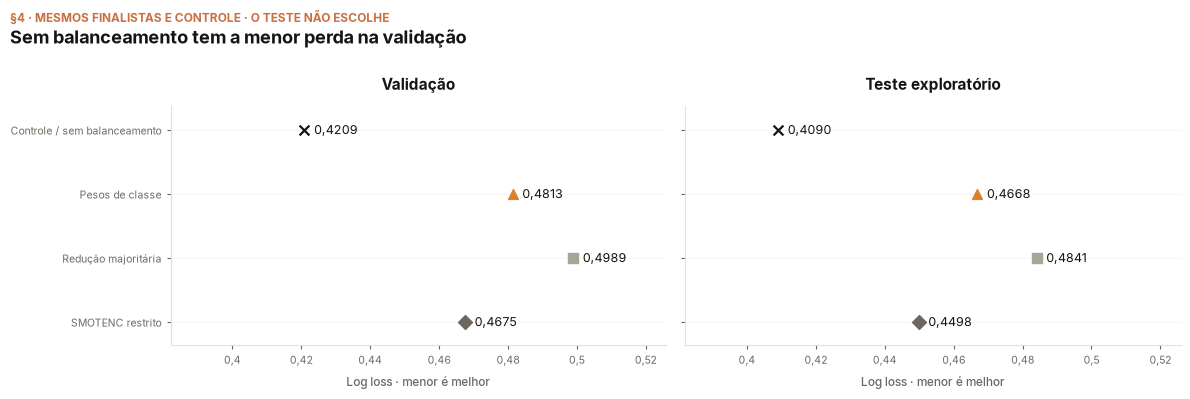

In [7]:
if FINAL:
    fig, axes = plt.subplots(1, 2, figsize=SP.FAIXA, sharex=True, sharey=True)
    for ax, split, titulo in zip(axes, ("val", "test"), ("Validação", "Teste exploratório")):
        for i, row in enumerate(modelos):
            color, _, marker = estilo_modelo(row)
            loss = metricas[(row["candidate_id"], split)]["logloss"]
            ax.scatter(loss, i, color=color, marker=marker, s=50, zorder=3)
            ax.annotate(SP.pt(loss, 4), (loss, i), xytext=(7, 0), textcoords="offset points", va="center", fontsize=9)
        ax.set_title(titulo)
        ax.set_xlabel("Log loss · menor é melhor")
        ax.margins(x=0.30, y=0.12)
        ax.set_yticks(range(len(modelos)), [nome_modelo(row) for row in modelos])
    axes[0].invert_yaxis()
    achado = f"{ROTULOS[selection['winner']['strategy']]} tem a menor perda na validação"
    print(achado)
    SP.titulo(fig, achado, "§4 · MESMOS FINALISTAS E CONTROLE · O TESTE NÃO ESCOLHE")
    SP.salvar(fig, "sample-balance-validation-test")
    plt.show()
    plt.close(fig)
else:
    print("Figura de perdas aguardando o agregado completo.")

**O que olhar.** A escala horizontal é compartilhada; o teste tem outra
população temporal. Resultados melhores ou piores precisam ser descritos nesse
condicionamento. Um limiar de classificação descritivo não foi otimizado aqui.

## §5 — Quanto cada finalista muda em relação ao controle

Definimos ganho como **perda do controle menos perda do finalista**. Ganho
positivo significa menor log loss; ganho negativo significa maior log loss.
O ganho relativo divide essa diferença pela perda do controle. Ele descreve
mudança da perda, não mudança da probabilidade de óbito.

In [8]:
ganhos = []
if FINAL:
    for row in selection["finalists"]:
        for split, titulo in (("val", "Validação"), ("test", "Teste exploratório")):
            referencia = metricas[(controle_id, split)]["logloss"]
            atual = metricas[(row["candidate_id"], split)]["logloss"]
            ganho = referencia - atual
            ganhos.append({"estratégia": ROTULOS[row["strategy"]], "partição": titulo,
                           "ganho log loss": ganho, "ganho relativo %": 100 * ganho / referencia,
                           "split": split, "candidato": row["candidate_id"]})
    print(SP.tabela(pd.DataFrame(ganhos).drop(columns=["split", "candidato"]),
                    {"ganho log loss": 4, "ganho relativo %": 2}))
    leitura_limiar = []
    for row in modelos:
        m = metricas[(row["candidate_id"], "test")]
        leitura_limiar.append({"modelo": nome_modelo(row), "limiar": m["threshold"],
                              "sensibilidade": m["sensitivity"], "especificidade": m["specificity"],
                              "verdadeiros positivos": m["tp"], "falsos positivos": m["fp"]})
    print("Descrição no limiar registrado, sem usá-lo para escolher o modelo:")
    print(SP.tabela(pd.DataFrame(leitura_limiar), 4))
else:
    print("Ganhos e descrição no limiar aguardam a comparação completa.")

         estratégia           partição ganho log loss ganho relativo %
  Sem balanceamento          Validação         0,0000             0,00
  Sem balanceamento Teste exploratório         0,0000             0,00
    Pesos de classe          Validação        -0,0604           -14,36
    Pesos de classe Teste exploratório        -0,0578           -14,14
Redução majoritária          Validação        -0,0780           -18,53
Redução majoritária Teste exploratório        -0,0750           -18,35
   SMOTENC restrito          Validação        -0,0466           -11,08
   SMOTENC restrito Teste exploratório        -0,0408            -9,97
Descrição no limiar registrado, sem usá-lo para escolher o modelo:
                      modelo limiar sensibilidade especificidade verdadeiros positivos falsos positivos
Controle / sem balanceamento 0,5000        0,1104         0,9773                   325              299
             Pesos de classe 0,5000        0,4231         0,8357                 1.246

Finalistas com menor perda no teste: 0
Nenhum finalista reduz a perda do teste frente ao controle


figura: figures_generated/sample-balance-gains-control.png


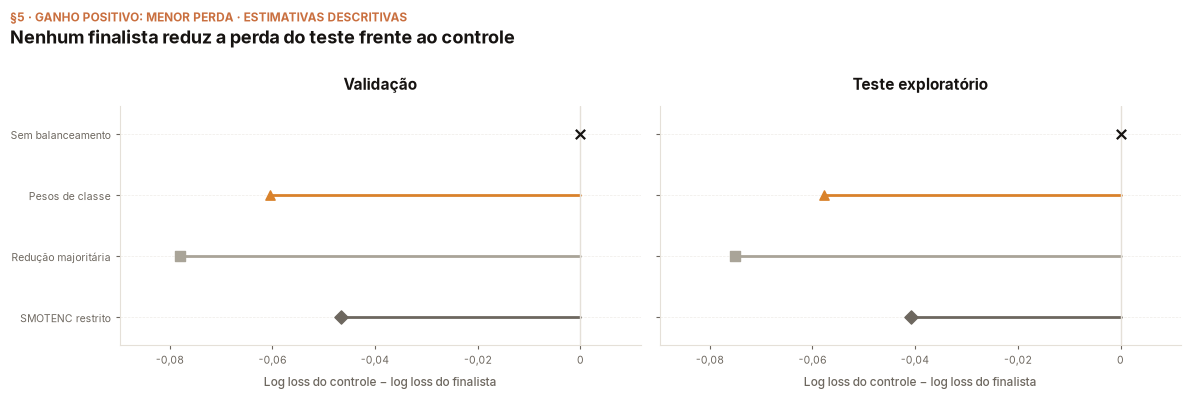

In [9]:
if FINAL:
    fig, axes = plt.subplots(1, 2, figsize=SP.FAIXA, sharex=True, sharey=True)
    for ax, split, titulo in zip(axes, ("val", "test"), ("Validação", "Teste exploratório")):
        linhas = [x for x in ganhos if x["split"] == split]
        for i, (row, linha) in enumerate(zip(selection["finalists"], linhas)):
            color, _, marker = estilo_modelo(row)
            valor = linha["ganho log loss"]
            ax.plot([0, valor], [i, i], color=color, linewidth=2)
            ax.scatter(valor, i, color=color, marker=marker, s=45, zorder=3)
        ax.axvline(0, color=SP.LINHA, linewidth=1)
        ax.set_title(titulo)
        ax.set_xlabel("Log loss do controle − log loss do finalista")
        ax.set_yticks(range(len(linhas)), [x["estratégia"] for x in linhas])
        ax.margins(x=0.15, y=0.15)
    axes[0].invert_yaxis()
    n_melhoram = sum(x["ganho log loss"] > 0 for x in ganhos if x["split"] == "test")
    print("Finalistas com menor perda no teste:", SP.pt_int(n_melhoram))
    if n_melhoram == 0:
        achado = "Nenhum finalista reduz a perda do teste frente ao controle"
    elif n_melhoram == 1:
        achado = "Um finalista reduz a perda do teste frente ao controle"
    else:
        achado = f"{SP.pt_int(n_melhoram)} finalistas reduzem a perda do teste frente ao controle"
    print(achado)
    SP.titulo(fig, achado, "§5 · GANHO POSITIVO: MENOR PERDA · ESTIMATIVAS DESCRITIVAS")
    SP.salvar(fig, "sample-balance-gains-control")
    plt.show()
    plt.close(fig)
else:
    print("Figura de ganhos aguardando o agregado completo.")

**O que olhar.** Detectar mais óbitos em um limiar pode vir acompanhado de mais
falsos alertas ou probabilidades piores. As tabelas separam essas perguntas.
As diferenças são estimativas descritivas; não são testes de significância
nem intervalos de incerteza sobre treinar novos modelos.

## §6 — Calibração: a probabilidade combina com a frequência?

Agrupamos previsões em faixas de mesma largura. Em cada faixa, comparamos a
probabilidade média prevista à frequência observada de óbito. A diagonal é a
referência de concordância; não representa prever perfeitamente cada pessoa.
A contagem mostra quanta informação sustenta cada ponto. Faixas vazias não
recebem uma frequência inventada.

As curvas abaixo descrevem probabilidades brutas. Elas não ajustam um
calibrador. Uma diferença pequena entre as médias globais pode esconder
desvios em partes da curva; por isso olhamos médias, curvas e contagens juntos.

In [10]:
# Contrato do agregado: reliability usa as faixas iguais de compute_metrics.
BORDAS = np.linspace(0, 1, 11)
calibracao = []
if FINAL:
    for row in modelos:
        for split in ("val", "test"):
            m = metricas[(row["candidate_id"], split)]
            bins = {int(b["bin"]): b for b in m["reliability"]}
            if len(bins) != len(m["reliability"]) or not set(bins).issubset(range(len(BORDAS) - 1)):
                raise ValueError("Faixas de calibração duplicadas ou fora do contrato.")
            if sum(b["n"] for b in bins.values()) != m["n"]:
                raise ValueError("Contagens das faixas não cobrem a partição.")
            for j in range(len(BORDAS) - 1):
                b = bins.get(j)
                calibracao.append({"modelo": nome_modelo(row), "candidato": row["candidate_id"],
                                   "split": split, "bin": j, "n": b["n"] if b else 0,
                                   "previsto": b["mean_predicted"] if b else np.nan,
                                   "observado": b["observed"] if b else np.nan})
    cal = pd.DataFrame(calibracao)
    print("Faixas de probabilidade:", SP.pt_int(len(BORDAS) - 1))
    for split, titulo in (("val", "Validação"), ("test", "Teste exploratório")):
        contagens = cal.loc[cal["split"] == split].pivot(index="bin", columns="modelo", values="n")
        contagens = contagens.reindex(columns=[nome_modelo(row) for row in modelos])
        contagens.index = [f"[{SP.pt(BORDAS[j], 1)}; {SP.pt(BORDAS[j+1], 1)}{']' if j == len(BORDAS)-2 else ')'}" for j in contagens.index]
        print(titulo, "· registros em cada faixa:")
        print(SP.tabela(contagens, index=True))
    resumo_cal = [{"modelo": nome_modelo(row), "partição": titulo,
                   "previsto médio": metricas[(row["candidate_id"], split)]["mean_predicted"],
                   "observado": metricas[(row["candidate_id"], split)]["observed"],
                   "desvio das médias": metricas[(row["candidate_id"], split)]["calibration_gap"],
                   "ECE nas faixas": metricas[(row["candidate_id"], split)]["ece_10_equal_width"]}
                  for row in modelos for split, titulo in (("val", "Validação"), ("test", "Teste exploratório"))]
    print("Médias e diagnóstico por faixas, sem modificar as previsões:")
    print(SP.tabela(pd.DataFrame(resumo_cal), 4))
else:
    print("Curvas e contagens finais aguardam seleção e avaliação completas.")

Faixas de probabilidade: 10
Validação · registros em cada faixa:
modelo     Controle / sem balanceamento Pesos de classe Redução majoritária SMOTENC restrito
[0,0; 0,1)                        6.319           6.824               4.031            5.666
[0,1; 0,2)                        5.228           3.305               2.345            4.468
[0,2; 0,3)                        5.393           3.081               2.779            3.822
[0,3; 0,4)                        4.105           2.985               3.874            3.406
[0,4; 0,5)                        2.132           2.710               4.476            2.953
[0,5; 0,6)                          762           2.310               4.003            2.126
[0,6; 0,7)                          184           1.672               2.088            1.274
[0,7; 0,8)                           25             923                 510              412
[0,8; 0,9)                            0             310                  42               21
[0,9;

Desvio absoluto das médias no teste: de 0,033 a 0,164


figura: figures_generated/sample-balance-calibration.png


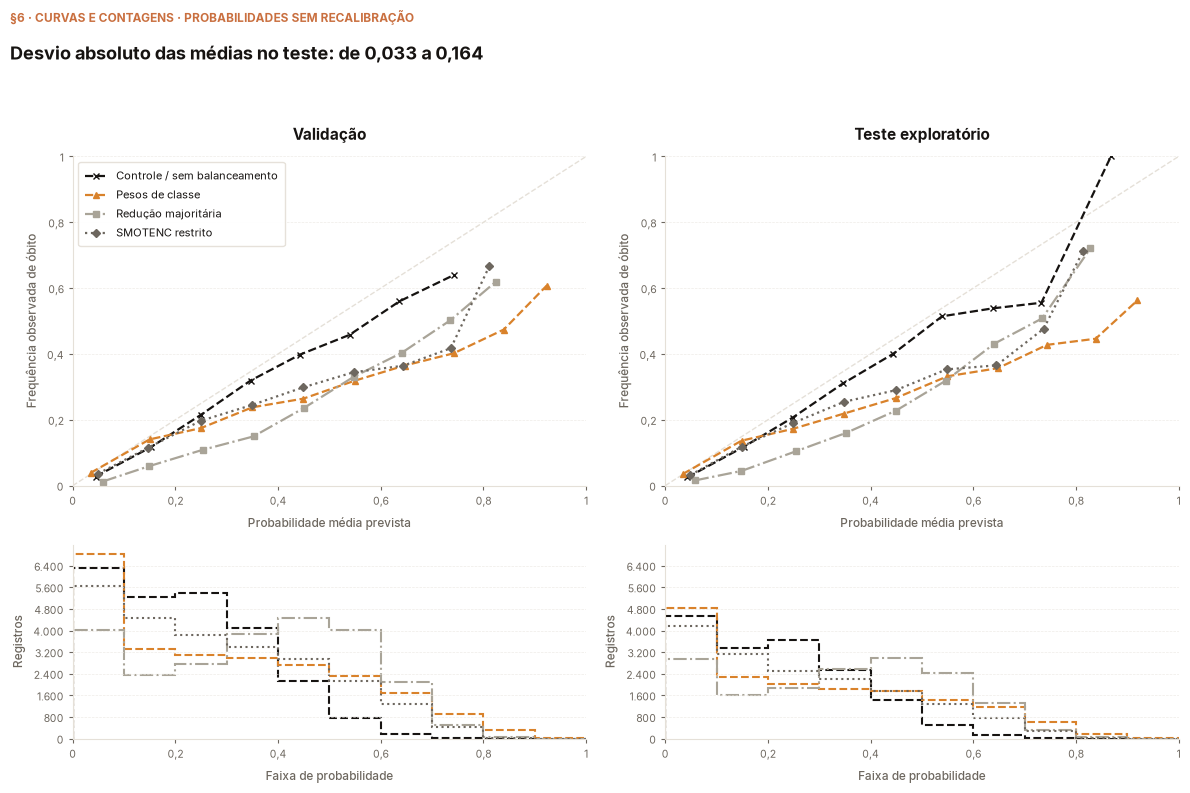

In [11]:
if FINAL:
    fig, axes = plt.subplots(2, 2, figsize=SP.PAINEL, gridspec_kw={"height_ratios": [1.7, 1]})
    for coluna, (split, titulo) in enumerate((("val", "Validação"), ("test", "Teste exploratório"))):
        ax, ax_n = axes[:, coluna]
        ax.plot([0, 1], [0, 1], color=SP.LINHA, linestyle="--", linewidth=1)
        for row in modelos:
            parte = cal.loc[(cal["split"] == split) & (cal["candidato"] == row["candidate_id"])].sort_values("bin")
            color, linestyle, marker = estilo_modelo(row)
            ax.plot(parte["previsto"], parte["observado"], color=color, linestyle=linestyle,
                    marker=marker, markersize=4, label=nome_modelo(row))
            ax_n.stairs(parte["n"].to_numpy(), BORDAS, color=color, linestyle=linestyle,
                        linewidth=1.5, label=nome_modelo(row))
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Probabilidade média prevista", ylabel="Frequência observada de óbito", title=titulo)
        ax_n.set(xlim=(0, 1), ylim=(0, max(1, float(cal["n"].max())) * 1.05),
                 xlabel="Faixa de probabilidade", ylabel="Registros")
        ax_n.yaxis.set_major_locator(MaxNLocator(integer=True))
    axes[0, 0].legend(fontsize=8, loc="upper left")
    desvios = [abs(metricas[(row["candidate_id"], "test")]["calibration_gap"]) for row in modelos]
    achado = f"Desvio absoluto das médias no teste: de {SP.pt(min(desvios), 3)} a {SP.pt(max(desvios), 3)}"
    print(achado)
    SP.titulo(fig, achado, "§6 · CURVAS E CONTAGENS · PROBABILIDADES SEM RECALIBRAÇÃO")
    SP.salvar(fig, "sample-balance-calibration")
    plt.show()
    plt.close(fig)
else:
    print("Figura de calibração aguardando o agregado completo.")

**O que olhar.** A curva deve ser lida junto das contagens. Poucos registros em
uma faixa tornam sua frequência mais instável; a figura não mostra intervalos
de confiança. ECE depende da divisão em faixas e não substitui a curva.
O desvio das médias, isoladamente, também não certifica boa calibração.

## §7 — Precisão da leitura e limite das conclusões

Os gráficos arredondam para leitura; a seleção usa os valores registrados
sem esse arredondamento. A tabela de auditoria mantém mais casas para conferir
diferenças pequenas. Arredondar a exibição não transforma resultados próximos
em empate estatístico.

In [12]:
if FINAL:
    auditoria = []
    for row in modelos:
        entrada = {"modelo": nome_modelo(row)}
        for split in ("val", "test"):
            entrada[f"log loss {split}"] = metricas[(row["candidate_id"], split)]["logloss"]
        auditoria.append(entrada)
    print("Auditoria numérica; esta precisão não é necessária para a fala da aula:")
    print(SP.tabela(pd.DataFrame(auditoria), 8))
    print("Finalistas e controle foram congelados antes do teste.")
    print("O teste já observado permanece exploratório.")
    print("Esta comparação não altera automaticamente o modelo das aulas.")
else:
    print("Resultados e auditoria numérica ainda pendentes; sem conclusões antecipadas.")
print("Trocar o preditor exige recalcular previsões, explicações, figuras e textos dependentes.")

Auditoria numérica; esta precisão não é necessária para a fala da aula:
                      modelo log loss val log loss test
Controle / sem balanceamento   0,42090336    0,40901958
             Pesos de classe   0,48134486    0,46684359
         Redução majoritária   0,49891336    0,48406620
            SMOTENC restrito   0,46752081    0,44981776
Finalistas e controle foram congelados antes do teste.
O teste já observado permanece exploratório.
Esta comparação não altera automaticamente o modelo das aulas.
Trocar o preditor exige recalcular previsões, explicações, figuras e textos dependentes.


## §8 — O que o livro diz e o que pertence ao estudo do modelo

Molnar apresenta PFI como avaliação de um preditor já treinado: mantemos o
modelo fixo, permutamos entradas da avaliação e recalculamos a perda. Escolher
coorte, amostra, balanceamento e hiperparâmetros acontece antes dessa etapa.
O ranking da PFI não escolhe automaticamente um modelo nem valida uso clínico.

Esta comparação permanece separada da seleção histórica e da busca no treino
completo que foi interrompida. Uma eventual adoção exige uma decisão explícita
e recomputação dos métodos afetados. O caminho didático chega à PFI sem
pressupor que todos os capítulos intermediários tenham sido executados.

Fontes: [protocolo do módulo](../COURSE_STUDY.md),
[Molnar, PFI](https://christophm.github.io/interpretable-ml-book/feature-importance.html),
[scikit-learn, escores probabilísticos e objetivo](https://scikit-learn.org/stable/modules/model_evaluation.html#which-scoring-function-should-i-use),
[scikit-learn, calibração](https://scikit-learn.org/stable/modules/calibration.html) e
[imbalanced-learn, reamostragem e avaliação](https://imbalanced-learn.org/stable/common_pitfalls.html).